# 01 — Prueba de concepto: test SADF sobre el Nasdaq (1995-2003)

**Capa 3 — Procesamiento** · Prueba de concepto del detector

**Pregunta:** si hubiéramos tenido el Radar de Burbujas en los años noventa, ¿se habría encendido la señal **antes del peak del Nasdaq en marzo de 2000**?

Si la respuesta es no, hay que revisar parámetros antes de seguir (o reevaluar la idea).

**Entradas:** índice `^IXIC` desde Yahoo Finance (1995-2003), guardado en `data/raw/`.
**Salidas:** estadístico SADF, valores críticos, gráfico y fecha de la primera señal.

La lógica del test vive en `src/sadf.py`; este notebook la importa y muestra cada paso.

## 1. ¿Qué es el test SADF y cómo detecta una burbuja?

**Idea económica.** En un mercado "normal" el precio se comporta aproximadamente como una **caminata aleatoria**: el cambio de mañana no depende del nivel de hoy. En una burbuja, en cambio, el precio sube *porque* ya subió (los compradores persiguen la tendencia): el crecimiento se vuelve **explosivo**, es decir, se autoalimenta.

**La regresión ADF** (Augmented Dickey-Fuller) mide justamente eso. Sobre el logaritmo del precio $y_t$ se estima:

$$\Delta y_t = \alpha + \beta\, y_{t-1} + \phi_1\, \Delta y_{t-1} + \varepsilon_t$$

| Valor de $\beta$ | Interpretación |
|---|---|
| $\beta < 0$ | El precio vuelve a una media (estacionario) |
| $\beta = 0$ | Caminata aleatoria (**hipótesis nula: no hay burbuja**) |
| $\beta > 0$ | Mientras más alto el precio, más sube: **crecimiento explosivo** |

El estadístico es el **t de $\beta$**. El ADF clásico busca valores muy *negativos* (estacionariedad); aquí miramos la cola **derecha**: valores grandes y positivos indican explosividad.

**¿Por qué "Supremum" (la S de SADF)?** Una burbuja no dura toda la muestra: aparece, crece y revienta. Si estimamos el ADF sobre toda la serie, la caída posterior "diluye" la burbuja. Phillips, Wu y Yu (2011) proponen estimar el ADF en **ventanas crecientes**: la primera con las $n_0$ primeras observaciones, luego $n_0+1$, $n_0+2$… hasta $T$. Obtenemos una **secuencia** de estadísticos ADF, uno por fecha:

- **SADF** = el máximo de esa secuencia. Responde *"¿hubo burbuja en algún momento de la muestra?"*.
- **Secuencia de ADF recursivos** = permite **fechar** la burbuja: la señal se enciende la primera semana en que el ADF supera su valor crítico y se apaga cuando vuelve a bajar. Esto es lo que alimentará el semáforo.

> **Por qué no graficar el SADF fecha a fecha:** el "SADF hasta la fecha *t*" es un máximo acumulado, así que nunca baja; una vez encendido, quedaría en rojo para siempre. Por eso para fechar se usa la secuencia de ADF (ver las decisiones al final).

**Parámetros:**

| Parámetro | Valor | Motivo |
|---|---|---|
| Frecuencia | Semanal (cierre del viernes) | Coherente con el reporte semanal; menos ruido |
| Variable | Logaritmo del precio | Una burbuja es crecimiento exponencial → lineal en logaritmos |
| Rezagos ADF | 1 (fijo) | Estándar en la literatura PWY/PSY; estable entre ventanas |
| Ventana mínima | $r_0 = 0{,}01 + 1{,}8/\sqrt{T}$ | Phillips, Shi y Yu (2015) |
| Valores críticos | Monte Carlo, 2.000 simulaciones | Ajustados al largo exacto de la muestra |

## 2. Preparación

Se agrega la raíz del proyecto al `path` para poder importar `src/sadf.py`.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src import sadf as S


# Estilo de gráficos: fondo claro, grilla tenue, ejes discretos
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#898781", "ytick.color": "#898781",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})
AZUL, NARANJA, GRIS, ROJO = "#2a78d6", "#eb6834", "#52514e", "#d03b3b"

## 3. Descarga de datos y respaldo en `data/raw/`

Se descarga `^IXIC` (Nasdaq Composite) diario desde el 1-ene-1995 hasta el 31-dic-2003. El CSV se guarda en `data/raw/` para que el análisis sea **reproducible**: si el archivo ya existe se lee desde disco y no se vuelve a descargar (así el resultado no cambia si Yahoo corrige datos históricos o no está disponible).

In [2]:
RUTA_CSV = RAIZ / "data" / "raw" / "IXIC_1995_2003.csv"

if RUTA_CSV.exists():
    diario = pd.read_csv(RUTA_CSV, index_col="Date", parse_dates=True)
    print(f"Leído desde disco: {RUTA_CSV.name}")
else:
    import yfinance as yf
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        diario = yf.download("^IXIC", start="1995-01-01", end="2004-01-01",
                             auto_adjust=False, progress=False, threads=False)
    diario.columns = diario.columns.get_level_values(0)  # quita el nivel 'Ticker'
    diario.index.name = "Date"
    diario.to_csv(RUTA_CSV)
    print(f"Descargado y guardado en: {RUTA_CSV}")

print(f"{len(diario)} días hábiles, del {diario.index.min():%d-%m-%Y} al {diario.index.max():%d-%m-%Y}")
diario.head()

Leído desde disco: IXIC_1995_2003.csv
2267 días hábiles, del 03-01-1995 al 31-12-2003


,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
1995-01-03,743.580017,743.580017,751.309998,743.530029,751.309998,248750000
1995-01-04,745.840027,745.840027,746.419983,740.469971,744.770020,290350000
1995-01-05,745.659973,745.659973,748.500000,745.130005,746.869995,297510000
1995-01-06,749.690002,749.690002,750.729980,745.760010,746.270020,312920000
1995-01-09,752.090027,752.090027,752.840027,750.099976,750.190002,267090000


## 4. Agregación semanal y logaritmo

Se toma el **último cierre ajustado de cada semana** (viernes, o el último día hábil si el viernes fue feriado) y se aplica logaritmo natural.

Para un índice, el cierre ajustado es igual al cierre (no hay dividendos que ajustar); se usa `Adj Close` para que el mismo código sirva después con acciones individuales.

In [3]:
semanal = diario["Adj Close"].resample("W-FRI").last().dropna()
log_precio = np.log(semanal).rename("log_precio")

T = len(log_precio)
r0, n0 = S.ventana_minima(T)
print(f"T = {T} semanas")
print(f"Ventana mínima: r0 = 0,01 + 1,8/√{T} = {r0:.4f}  →  n0 = {n0} semanas "
      f"(la primera ventana termina el {log_precio.index[n0 - 1]:%d-%m-%Y})")

T = 470 semanas
Ventana mínima: r0 = 0,01 + 1,8/√470 = 0.0930  →  n0 = 43 semanas (la primera ventana termina el 27-10-1995)


**Cómo leerlo:** con 470 semanas, la primera regresión usa 43 semanas (~10 meses). Antes de esa fecha no hay suficientes datos para estimar, por lo que el radar no puede emitir señal en 1995.

## 5. Verificación: nuestra función vs. `statsmodels`

`src/sadf.py` no llama a `statsmodels.adfuller` en cada ventana. Usa **sumas acumuladas**: al pasar de una ventana a la siguiente solo se agrega una fila, así que las matrices $X'X$ y $X'y$ de todas las ventanas se obtienen con una suma acumulada y todas las regresiones se resuelven de una vez. Esto es cientos de veces más rápido, lo que hace viable el Monte Carlo.

Antes de confiar en ella, comparamos contra `statsmodels` en tres ventanas:

In [4]:
from statsmodels.tsa.stattools import adfuller

secuencia = S.secuencia_adf(log_precio, n0, rezagos=1)

comparacion = pd.DataFrame([
    {"ventana (semanas)": w,
     "src/sadf.py": secuencia.iloc[w - n0],
     "statsmodels": adfuller(log_precio.to_numpy()[:w], maxlag=1, autolag=None, regression="c",
                                result_object=False)[0]}
    for w in (n0, 200, T)
])
comparacion["diferencia"] = (comparacion["src/sadf.py"] - comparacion["statsmodels"]).abs()
comparacion

,ventana (semanas),src/sadf.py,statsmodels,diferencia
0,43,-0.932059,-0.932059,3.387290e-13
1,200,-1.557332,-1.557332,8.200107e-13
2,470,-1.957087,-1.957087,4.281020e-13


**Cómo leerlo:** las diferencias son del orden de $10^{-12}$ (error de redondeo de punto flotante). La implementación rápida entrega exactamente el mismo estadístico que la librería estándar.

## 6. Valores críticos por simulación Monte Carlo

El estadístico SADF **no sigue una distribución conocida** (como la t de Student), así que sus valores críticos se obtienen por simulación:

1. Se simulan 2.000 series bajo la **hipótesis nula** (sin burbuja): una caminata aleatoria del mismo largo $T$, con una deriva despreciable ($y_t = T^{-1} + y_{t-1} + \varepsilon_t$, como en Phillips, Shi y Yu, 2015).
2. A cada serie se le aplica exactamente el mismo procedimiento (misma ventana mínima, mismo rezago).
3. El **valor crítico al 95%** es el percentil 95 de los 2.000 estadísticos simulados: solo el 5% de las series *sin* burbuja supera ese valor por azar.

Se obtienen dos tipos de valores críticos:
- **Para el SADF** (un número): percentil del máximo de cada secuencia simulada.
- **Para la secuencia** (uno por ventana): percentil del ADF simulado en cada ventana. Sirve para fechar la señal semana a semana.

Se fija la semilla (`semilla=42`) para que el resultado sea reproducible.

In [5]:
cv_sadf, cv_secuencia = S.valores_criticos_mc(T, n0, rezagos=1, n_sim=2000, semilla=42)
cv95_secuencia = pd.Series(cv_secuencia[1], index=secuencia.index, name="cv95")

estadistico_sadf = S.sadf(log_precio, n0)
pd.DataFrame({
    "Estadístico SADF": [estadistico_sadf] * 3,
    "Valor crítico": [cv_sadf[q] for q in (0.90, 0.95, 0.99)],
}, index=["90%", "95%", "99%"]).assign(
    **{"¿Rechaza H0 (hay burbuja)?": lambda d: np.where(d["Estadístico SADF"] > d["Valor crítico"], "Sí", "No")}
).round(3)

,Estadístico SADF,Valor crítico,¿Rechaza H0 (hay burbuja)?
90%,1.611,1.174,Sí
95%,1.611,1.418,Sí
99%,1.611,2.018,No


**Cómo leerlo:** el SADF de la muestra 1995-2003 supera el valor crítico al 90% y al 95%: **se rechaza la hipótesis de caminata aleatoria, hay evidencia de crecimiento explosivo**. No alcanza el umbral del 99%, así que la evidencia es sólida pero no abrumadora.

## 7. Fechado de la señal: secuencia ADF vs. valor crítico al 95%

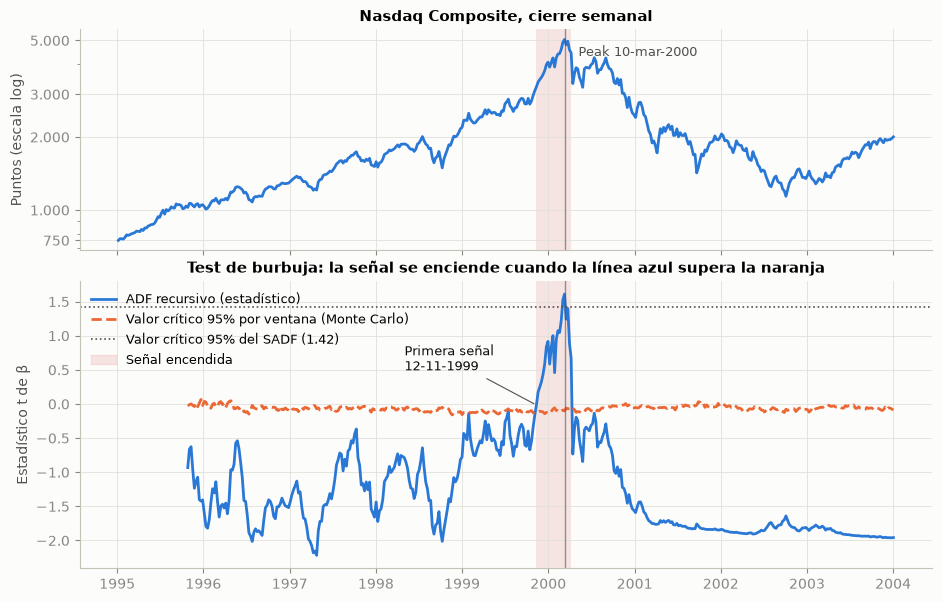

Episodios con la señal encendida:


,inicio,fin,semanas
0,1999-11-12,2000-04-07,22


In [6]:
encendida = secuencia > cv95_secuencia
primera = S.primera_senal(secuencia, cv95_secuencia)
PEAK = pd.Timestamp("2000-03-10")

# Episodios: tramos consecutivos de semanas con la señal encendida
grupos = (encendida != encendida.shift()).cumsum()[encendida]
episodios = pd.DataFrame([
    {"inicio": g.index.min().date(), "fin": g.index.max().date(), "semanas": len(g)}
    for _, g in grupos.groupby(grupos)
])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                               gridspec_kw={"height_ratios": [1, 1.3], "hspace": 0.12})

# Panel superior: precio del Nasdaq (escala logarítmica)
ax1.plot(semanal.index, semanal, color=AZUL, lw=2)
ax1.set_yscale("log")
ax1.set_yticks([750, 1000, 2000, 3000, 5000])
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", ".")))
ax1.yaxis.set_minor_formatter(plt.NullFormatter())
ax1.set_ylabel("Puntos (escala log)")
ax1.set_title("Nasdaq Composite, cierre semanal")

# Panel inferior: secuencia de ADF recursivos vs. valores críticos
ax2.plot(secuencia.index, secuencia, color=AZUL, lw=2, label="ADF recursivo (estadístico)")
ax2.plot(cv95_secuencia.index, cv95_secuencia, color=NARANJA, lw=2, ls="--",
         label="Valor crítico 95% por ventana (Monte Carlo)")
ax2.axhline(cv_sadf[0.95], color=GRIS, lw=1.2, ls=":",
            label=f"Valor crítico 95% del SADF ({cv_sadf[0.95]:.2f})")
ax2.set_ylabel("Estadístico t de β")
ax2.set_title("Test de burbuja: la señal se enciende cuando la línea azul supera la naranja")

for ax in (ax1, ax2):
    for _, ep in episodios.iterrows():
        ax.axvspan(pd.Timestamp(ep["inicio"]), pd.Timestamp(ep["fin"]), color=ROJO, alpha=0.12, lw=0)
    ax.axvline(PEAK, color=GRIS, lw=1, ls="-", alpha=0.6)
ax1.annotate("Peak 10-mar-2000", xy=(PEAK, semanal.max()), xytext=(10, -4),
             textcoords="offset points", color=GRIS, fontsize=9, va="top")
ax2.annotate(f"Primera señal\n{primera:%d-%m-%Y}", xy=(primera, secuencia[primera]),
             xytext=(-95, 25), textcoords="offset points", color="#0b0b0b", fontsize=9,
             arrowprops=dict(arrowstyle="-", color=GRIS, lw=0.8))

ax2.fill_between([], [], color=ROJO, alpha=0.12, label="Señal encendida")
ax2.legend(loc="upper left", frameon=False, fontsize=9)
ax2.xaxis.set_major_locator(mdates.YearLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.show()

print("Episodios con la señal encendida:")
episodios

**Cómo leer el gráfico:**
- **Panel superior:** el Nasdaq en escala logarítmica. En esta escala, una pendiente que se empina (1999-2000) es crecimiento más rápido que exponencial.
- **Panel inferior:** la línea azul es el estadístico ADF de cada ventana creciente. Mientras está bajo la línea naranja (su valor crítico al 95%), el comportamiento es compatible con una caminata aleatoria. Cuando la supera, la zona se sombrea en rojo: **crecimiento explosivo**.
- La línea gris punteada es el valor crítico del SADF de toda la muestra: un umbral más exigente, que corrige por haber mirado muchas ventanas (ver sección 9).

In [7]:
semanas_antes = (PEAK - primera).days // 7
print(f"Primera señal (ADF > valor crítico 95% por ventana): {primera:%d-%m-%Y}")
print(f"Peak del Nasdaq:                                     {PEAK:%d-%m-%Y}")
print(f"¿Antes de marzo de 2000?  {'SÍ' if primera < pd.Timestamp('2000-03-01') else 'NO'}"
      f"  → {semanas_antes} semanas de anticipación")

primera_estricta = S.primera_senal(secuencia, cv_sadf[0.95])
print(f"\nCon el umbral estricto del SADF ({cv_sadf[0.95]:.2f}): primera señal el {primera_estricta:%d-%m-%Y}"
      f" ({(PEAK - primera_estricta).days // 7} semanas antes del peak)")

# Magnitud de la caída posterior
cierre = diario["Close"]
fecha_peak, fecha_min = cierre.idxmax(), cierre[cierre.idxmax():].idxmin()
print(f"\nCaída del Nasdaq: {cierre.max():,.0f} ({fecha_peak:%d-%m-%Y}) → {cierre[fecha_min]:,.0f} "
      f"({fecha_min:%d-%m-%Y}) = {cierre[fecha_min] / cierre.max() - 1:.1%}")

Primera señal (ADF > valor crítico 95% por ventana): 12-11-1999
Peak del Nasdaq:                                     10-03-2000
¿Antes de marzo de 2000?  SÍ  → 17 semanas de anticipación

Con el umbral estricto del SADF (1.42): primera señal el 03-03-2000 (1 semanas antes del peak)

Caída del Nasdaq: 5,049 (10-03-2000) → 1,114 (09-10-2002) = -77.9%


## 8. Sensibilidad: ¿qué pasa con datos diarios?

Como chequeo de la decisión de usar datos semanales, repetimos el procedimiento con datos diarios (con la ventana mínima recalculada para el nuevo $T$; 500 simulaciones bastan para esta comparación).

In [8]:
log_diario = np.log(diario["Adj Close"].dropna())
Td = len(log_diario)
_, n0d = S.ventana_minima(Td)
secuencia_d = S.secuencia_adf(log_diario, n0d)
cv_sadf_d, cv_sec_d = S.valores_criticos_mc(Td, n0d, n_sim=500, semilla=42)
encendida_d = secuencia_d > cv_sec_d[1]

print(f"Diario: T = {Td}, n0 = {n0d} días")
print(f"SADF = {secuencia_d.max():.3f} vs. valor crítico 95% = {cv_sadf_d[0.95]:.3f}")
print(f"Primera señal: {S.primera_senal(secuencia_d, cv_sec_d[1]):%d-%m-%Y}")
print("Días con señal encendida por año:")
encendida_d.groupby(encendida_d.index.year).sum()

Diario: T = 2267, n0 = 108 días
SADF = 1.410 vs. valor crítico 95% = 1.490
Primera señal: 16-06-1995
Días con señal encendida por año:


Date
1995    37
1996     0
1997     0
1998     0
1999    34
2000    70
2001     0
2002     0
2003     0
Name: adf_recursivo, dtype: int64

**Cómo leerlo:** con datos diarios el SADF de la muestra **no** supera su valor crítico al 95%, y la secuencia se enciende por primera vez en 1995 (con ventanas cortas y ruidosas), mucho antes de la burbuja propiamente tal. El ruido diario infla la varianza del estimador y reduce la potencia del test. **Esto respalda la decisión de trabajar con datos semanales.**

## 9. ¿Qué tan confiables son los valores críticos?

Hay dos fuentes de incertidumbre distintas:

**a) Error de simulación (Monte Carlo).** Con un número finito de simulaciones, el percentil 95 estimado varía según la semilla. Lo medimos repitiendo el cálculo con 5 semillas distintas y comparándolo con una corrida grande de 20.000 simulaciones.

In [9]:
filas = []
for semilla in (1, 2, 3, 4, 5):
    cv, _ = S.valores_criticos_mc(T, n0, n_sim=2000, semilla=semilla)
    filas.append({"corrida": f"2.000 sim, semilla {semilla}", "cv 95% SADF": cv[0.95]})
cv_grande, _ = S.valores_criticos_mc(T, n0, n_sim=20000, semilla=2026)
filas.append({"corrida": "20.000 sim (referencia)", "cv 95% SADF": cv_grande[0.95]})

tabla_mc = pd.DataFrame(filas).set_index("corrida").round(3)
dispersion = tabla_mc.iloc[:5, 0].std()
print(f"Desviación estándar entre semillas (2.000 sim): {dispersion:.3f}")
print(f"SADF observado: {estadistico_sadf:.3f}  |  margen sobre el cv 95% de referencia: "
      f"{estadistico_sadf - cv_grande[0.95]:+.3f}")
fecha_ref = S.primera_senal(secuencia, cv_grande[0.95])
print(f"Primera señal con el umbral estricto de referencia ({cv_grande[0.95]:.3f}): {fecha_ref:%d-%m-%Y}")
tabla_mc

Desviación estándar entre semillas (2.000 sim): 0.037
SADF observado: 1.611  |  margen sobre el cv 95% de referencia: +0.109
Primera señal con el umbral estricto de referencia (1.502): 03-03-2000


,cv 95% SADF
corrida,
"2.000 sim, semilla 1",1.522
"2.000 sim, semilla 2",1.436
"2.000 sim, semilla 3",1.516
"2.000 sim, semilla 4",1.508
"2.000 sim, semilla 5",1.469
20.000 sim (referencia),1.502


**b) Problema de comparaciones múltiples al fechar.** El valor crítico *por ventana* controla un 5% de falsas alarmas **en cada semana por separado**. Pero el radar mira más de 400 semanas: bajo la hipótesis nula, la probabilidad de que la señal se encienda *alguna vez* por azar es mucho mayor que 5%. Lo medimos directamente sobre series simuladas sin burbuja:

In [10]:
rng = np.random.default_rng(7)
n_prueba = 2000
alguna_vez, alguna_vez_estricta = 0, 0
for _ in range(n_prueba):
    y = np.cumsum(1.0 / T + rng.standard_normal(T))
    seq_nula = S.adf_recursivo(y, n0)
    alguna_vez += (seq_nula > cv_secuencia[1]).any()
    alguna_vez_estricta += (seq_nula > cv_sadf[0.95]).any()

print(f"Series SIN burbuja en que la señal se enciende al menos una semana:")
print(f"  - con el valor crítico por ventana (línea naranja):  {alguna_vez / n_prueba:.1%}")
print(f"  - con el valor crítico del SADF (línea gris):        {alguna_vez_estricta / n_prueba:.1%}")

Series SIN burbuja en que la señal se enciende al menos una semana:
  - con el valor crítico por ventana (línea naranja):  66.4%
  - con el valor crítico del SADF (línea gris):        6.6%


**Cómo leerlo y conclusión sobre la confiabilidad:**

- **Error de simulación: moderado.** Con 2.000 simulaciones el valor crítico al 95% varía entre semillas (desviación ≈ 0,04); la semilla 42 usada arriba (1,418) quedó en el extremo bajo frente a la referencia de 20.000 simulaciones (≈ 1,50). La conclusión **"hay burbuja" no cambia** (el SADF observado, 1,611, supera el valor crítico en todas las corridas), pero la **fecha** de la señal con el umbral estricto sí es sensible a este error. Como la simulación es rápida (~1 segundo por 2.000), conviene usar más simulaciones en producción (decisión pendiente).
- **Supuestos del modelo nulo: limitación real.** Los valores críticos suponen que, sin burbuja, el log-precio es una caminata aleatoria con shocks normales y varianza constante. Los retornos reales tienen colas gruesas y volatilidad cambiante (por ejemplo, 2001-2002), lo que puede distorsionar el tamaño del test. Una mejora posible es el *wild bootstrap* (Phillips y Shi, 2020), que no se implementa en el MVP.
- **Comparaciones múltiples: relevante para el semáforo.** El valor crítico por ventana es el método de fechado de Phillips, Wu y Yu (2011), pero sobre una serie sin burbuja puede encender la señal al menos una vez con una frecuencia muy superior al 5%. El umbral del SADF (línea gris) controla esa tasa al 5% en toda la muestra, a costa de avisar más tarde. **La elección del umbral para el semáforo (verde/amarillo/rojo) se resuelve en el diseño del semáforo (notebooks 03 y 03b).**
- **Contraste con tablas publicadas:** queda pendiente comparar con la tabla 1 de Phillips, Shi y Yu (2015) para una muestra de tamaño similar.

## 10. Conclusión de la prueba de concepto

In [11]:
print("RESUMEN — Prueba de concepto SADF, Nasdaq 1995-2003 (semanal, 1 rezago, r0 = 0,01 + 1,8/√T)")
print(f"  Observaciones: T = {T} semanas | ventana mínima n0 = {n0}")
print(f"  SADF = {estadistico_sadf:.3f} | valor crítico 95% = {cv_sadf[0.95]:.3f} → "
      f"{'hay' if estadistico_sadf > cv_sadf[0.95] else 'no hay'} evidencia de burbuja al 95%")
print(f"  Primera señal (cv por ventana): {primera:%d-%m-%Y}, {semanas_antes} semanas antes del peak")
print(f"  Primera señal (cv SADF):        {primera_estricta:%d-%m-%Y}, {(PEAK - primera_estricta).days // 7} semanas antes del peak")
print(f"  Episodios con señal encendida: {len(episodios)}")

RESUMEN — Prueba de concepto SADF, Nasdaq 1995-2003 (semanal, 1 rezago, r0 = 0,01 + 1,8/√T)
  Observaciones: T = 470 semanas | ventana mínima n0 = 43
  SADF = 1.611 | valor crítico 95% = 1.418 → hay evidencia de burbuja al 95%
  Primera señal (cv por ventana): 12-11-1999, 17 semanas antes del peak
  Primera señal (cv SADF):        03-03-2000, 1 semanas antes del peak
  Episodios con señal encendida: 1


**Veredicto: la prueba de concepto se supera, con un matiz importante sobre el umbral.**

- El test **detecta la burbuja puntocom**: el SADF de la muestra rechaza la caminata aleatoria al 95%.
- Con el **valor crítico por ventana** (método de fechado de Phillips, Wu y Yu, 2011), la señal se enciende el **12-11-1999, 17 semanas antes del peak**, en un único episodio continuo hasta abril de 2000. **Sí, antes de marzo de 2000.**
- Con el **umbral estricto del SADF**, la señal llega recién a inicios de marzo de 2000, prácticamente en el peak: casi sin anticipación.
- El umbral por ventana avisa antes pero, en series sin burbuja, da al menos una falsa alarma en una alta proporción de los casos (sección 9). Hay un **trade-off entre anticipación y falsas alarmas** que debe resolverse al diseñar el semáforo. Una opción natural: **amarillo** = supera el umbral por ventana; **rojo** = supera el umbral del SADF.

**Limitaciones de este resultado** (se suman a las de `docs/metodologia.md`, sección 8):
1. Es un solo episodio, analizado *ex post*; la muestra parte en 1995, ya dentro del alza.
2. El test detecta crecimiento explosivo, no predice la fecha de la caída: la señal se apaga cerca del peak porque el precio deja de acelerar.
3. Los valores críticos dependen de supuestos (normalidad, varianza constante) que los datos reales no cumplen del todo.

**Decisiones de diseño de este paso:** frecuencia semanal, 1 rezago fijo, valores críticos por Monte Carlo con 2.000 simulaciones, y fechado con la secuencia de ADF recursivos en lugar del SADF acumulado.